# 06 Race prediction

Probability that each driver wins one chosen race, using only information known before the start. All the logic is in `src/prediction.py`: the model is trained on the seasons before the race and applied to the drivers of that race, with variables built from previous races only (notebook 04). This is the same computation the final application will use.

In [1]:
import sys
from pathlib import Path

# find the repo root (the folder that contains src/) wherever the notebook is started from
cwd = Path.cwd()
root = next(p for p in [cwd, cwd / "AdvanceData", *cwd.parents] if (p / "src").is_dir())
sys.path.insert(0, str(root / "src"))

import modeling
import plots
import prediction

In [2]:
data = modeling.load_model_table()
races = prediction.list_races(data)
print(len(races), "races can be predicted, from", races["race_id"].min(), "to", races["race_id"].max())

213 races can be predicted, from 201701 to 202620


## Choose a race

Change `YEAR` and `ROUND` to look at another race.

In [3]:
YEAR, ROUND = 2024, 1
race_id = YEAR * 100 + ROUND

ranking = prediction.predict_race(data, race_id)
display(ranking.round(3))
plots.save_table(ranking.round(4).set_index("rank"), f"ranking_{race_id}.csv")

,rank,driver,driver_id,team,grid,driver_form3,driver_wins_before,team_pace3,win_probability,race_share
0,1,Max Verstappen,max_verstappen,Red Bull,1,25.333,54,0.000,0.726,0.672
1,2,Leclerc,leclerc,Ferrari,2,12.000,5,0.552,0.156,0.144
2,3,Perez,perez,Red Bull,5,13.000,6,0.000,0.059,0.055
3,4,Russell,russell,Mercedes,3,6.333,1,0.668,0.053,0.049
4,5,Sainz,sainz,Ferrari,4,5.333,2,0.552,0.032,0.029
5,6,Alonso,alonso,Aston Martin lineage,6,7.667,32,0.737,0.023,0.022
6,7,Norris,norris,McLaren,7,9.667,0,0.545,0.015,0.014
7,8,Hamilton,hamilton,Mercedes,9,4.000,103,0.668,0.008,0.008
8,9,Piastri,piastri,McLaren,8,3.333,0,0.545,0.004,0.004
9,10,Stroll,stroll,Aston Martin lineage,12,7.000,0,0.737,0.001,0.001


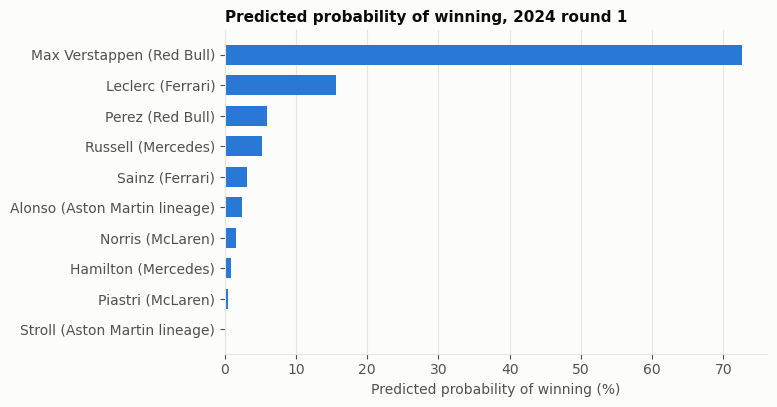

In [4]:
fig = plots.plot_probability_ranking(ranking, f"Predicted probability of winning, {YEAR} round {ROUND}")
plots.save_figure(fig, f"probability_ranking_{race_id}.png")

*Figure.* Predicted probability of winning for the ten most likely drivers of the selected race. The probabilities come from the logistic regression trained on earlier seasons only. Drivers are shown by id and team.

## What actually happened

Only for checking: the real winner of that race (not used by the model).

In [5]:
winner = data[(data["race_id"] == race_id) & (data["win"] == 1)][["driver_id", "team"]]
print("winner:", winner.iloc[0].to_dict())
print("rank given by the model:", int(ranking.index[ranking["driver_id"] == winner.iloc[0]["driver_id"]][0]) + 1)

winner: {'driver_id': 'max_verstappen', 'team': 'Red Bull'}
rank given by the model: 1
